In [1]:
# Install Java (Colab normally runs on Ubuntu)
!apt-get -qq update
!apt-get -qq install -y openjdk-17-jdk
!java -version
!javac -version

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package at-spi2-common.
(Reading database ... 122813 files and directories currently installed.)
Preparing to unpack .../00-at-spi2-common_2.52.0-1build1_all.deb ...
Unpacking at-spi2-common (2.52.0-1build1) ...
Selecting previously unselected package libatspi2.0-0t64:amd64.
Preparing to unpack .../01-libatspi2.0-0t64_2.52.0-1build1_amd64.deb ...
Unpacking libatspi2.0-0t64:amd64 (2.52.0-1build1) ...
Selecting previously unselected package libxtst6:amd64.
Preparing to unpack .../02-libxtst6_2%3a1.2.3-1.1ubuntu0.1_amd64.deb ...
Unpacking libxtst6:amd64 (2:1.2.3-1.1ubuntu0.1) ...
Selecting previously unselected package session-migration.
Preparing to unpack .../03-session-migration_0.3.9build1_amd64.deb ...
Unpacking session-migration (0.3.9build1) ...
Selecting previousl

## 1. Create and compile the Java implementation

The Java file includes all six required collection/design exercises and Q7 redesign. It also writes repeatable timing data to `q1_measurements.csv` through `q7_measurements.csv`. Q3 deliberately demonstrates the broken implementation first, then the corrected `hashCode()` implementation.

In [2]:
%%writefile Assignment2.java

import java.util.*;
import java.io.*;

public class Assignment2 {
    static Random random = new Random(42);
    static volatile long sink = 0;

    static long timeNanos(Runnable r) {
        long start = System.nanoTime();
        r.run();
        return System.nanoTime() - start;
    }

    // ---------------- Q1: String vs StringBuilder vs StringBuffer ----------------
    static String ticketPlus(int tickets, int fields) {
        String result = "";
        for (int t=0; t<tickets; t++) {
            String ticket = "";
            for (int f=0; f<fields; f++) ticket += "FIELD" + f + "=" + t + ";";
            result = ticket;
        }
        return result;
    }
    static String ticketBuilder(int tickets, int fields) {
        String result = "";
        for (int t=0; t<tickets; t++) {
            StringBuilder b = new StringBuilder();
            for (int f=0; f<fields; f++) b.append("FIELD").append(f).append("=").append(t).append(";");
            result = b.toString();
        }
        return result;
    }
    static String ticketBuffer(int tickets, int fields) {
        String result = "";
        for (int t=0; t<tickets; t++) {
            StringBuffer b = new StringBuffer();
            for (int f=0; f<fields; f++) b.append("FIELD").append(f).append("=").append(t).append(";");
            result = b.toString();
        }
        return result;
    }
    static void q1(PrintWriter out) {
        System.out.println("\\nQ1 — String construction benchmark (nanoseconds; best of 3 after warm-up)");
        out.println("Q1,workload,method,nanos");
        int[][] workloads={{1,10},{1000,50},{3000,100}};
        for (int[] w:workloads) {
            int tickets=w[0], fields=w[1];
            Runnable[] jobs={()->sink=ticketPlus(tickets,fields).length(),
                ()->sink=ticketBuilder(tickets,fields).length(),
                ()->sink=ticketBuffer(tickets,fields).length()};
            String[] names={"StringPlus","StringBuilder","StringBuffer"};
            for(int i=0;i<3;i++) {
                jobs[i].run();
                long best=Long.MAX_VALUE;
                for(int r=0;r<3;r++) best=Math.min(best,timeNanos(jobs[i]));
                System.out.println(tickets+" tickets x "+fields+" fields | "+names[i]+" | "+best);
                out.println("Q1,"+tickets+"x"+fields+","+names[i]+","+best);
            }
        }
    }

    // ---------------- Q2: List and Deque comparisons ----------------
    static void q2(PrintWriter out) {
        System.out.println("\\nQ2 — List operations benchmark (nanoseconds; one operation batch)");
        out.println("Q2,size,structure,operation,nanos");
        int[] sizes={1000,5000,10000};
        for(int n:sizes) {
            ArrayList<Integer> a=new ArrayList<>();
            LinkedList<Integer> l=new LinkedList<>();
            ArrayDeque<Integer> d=new ArrayDeque<>();
            for(int i=0;i<n;i++){a.add(i);l.add(i);d.addLast(i);}
            int reps=Math.min(n,2000);
            long ta=timeNanos(()->{for(int i=0;i<reps;i++)a.add(a.size(),i);});
            long tl=timeNanos(()->{for(int i=0;i<reps;i++)l.addLast(i);});
            out.println("Q2,"+n+",ArrayList,addEnd,"+ta);
            out.println("Q2,"+n+",LinkedList,addEnd,"+tl);
            long af=timeNanos(()->{for(int i=0;i<reps;i++)a.add(0,i);});
            long lf=timeNanos(()->{for(int i=0;i<reps;i++)l.add(0,i);});
            long df=timeNanos(()->{for(int i=0;i<reps;i++)d.addFirst(i);});
            out.println("Q2,"+n+",ArrayList,addFront,"+af);
            out.println("Q2,"+n+",LinkedList,addFront,"+lf);
            out.println("Q2,"+n+",ArrayDeque,addFront,"+df);
            int mid=a.size()/2;
            long am=timeNanos(()->{for(int i=0;i<reps;i++){a.add(a.size()/2,i);a.remove(a.size()/2);}});
            long lm=timeNanos(()->{for(int i=0;i<reps;i++){l.add(l.size()/2,i);l.remove(l.size()/2);}});
            out.println("Q2,"+n+",ArrayList,insertRemoveMiddle,"+am);
            out.println("Q2,"+n+",LinkedList,insertRemoveMiddle,"+lm);
            int idx=a.size()/2;
            long ag=timeNanos(()->{for(int i=0;i<10000;i++)sink+=a.get(idx);});
            long lg=timeNanos(()->{for(int i=0;i<10000;i++)sink+=l.get(idx);});
            out.println("Q2,"+n+",ArrayList,getK,"+ag);
            out.println("Q2,"+n+",LinkedList,getK,"+lg);
            long ai=timeNanos(()->{long s=0;for(int x:a)s+=x;sink=s;});
            long li=timeNanos(()->{long s=0;for(int x:l)s+=x;sink=s;});
            out.println("Q2,"+n+",ArrayList,iterate,"+ai);
            out.println("Q2,"+n+",LinkedList,iterate,"+li);
            System.out.println("Completed size "+n);
        }
        System.out.println("Q2 interpretation: ArrayList suits append/index-heavy playlists; LinkedList suits edits through an existing iterator; ArrayDeque suits double-ended queues.");
    }

    // ---------------- Q3: equals/hashCode contract ----------------
    static class Student {
        final String regNo, name;
        Student(String r,String n){regNo=r;name=n;}
        public boolean equals(Object o){return o instanceof Student && regNo.equals(((Student)o).regNo);}
        // TODO 1 completed: equal registration numbers produce equal hash codes.
        public int hashCode(){return Objects.hash(regNo);}
        public String toString(){return regNo+" "+name;}
    }
    static class BadStudent {
        String regNo;
        BadStudent(String r){regNo=r;}
        public boolean equals(Object o){return o instanceof BadStudent && regNo.equals(((BadStudent)o).regNo);}
        // Deliberately no hashCode override: demonstrates broken contract.
    }
    static void q3() {
        System.out.println("\\nQ3 — HashSet equals/hashCode contract");
        Set<BadStudent> bad=new HashSet<>();
        bad.add(new BadStudent("R1")); bad.add(new BadStudent("R1"));
        System.out.println("Broken class, two equal IDs inserted: set size may be 2 (observed "+bad.size()+")");
        Set<Student> good=new HashSet<>();
        good.add(new Student("R1","Arun")); good.add(new Student("R2","Divya")); good.add(new Student("R1","Arun"));
        System.out.println("Correct class, unique students: "+good.size()+" (expected 2)");
        Set<Student> mutableTest=new HashSet<>();
        Student fixed=new Student("R3","Kavi"); mutableTest.add(fixed);
        System.out.println("Immutable key design: contains after insertion = "+mutableTest.contains(fixed));
        System.out.println("Note: changing a field used by hashCode after insertion can make lookup/removal fail; use immutable key fields.");
        System.out.println("Alternative: TreeSet with comparator on regNo or HashMap keyed by regNo also de-duplicates by ID.");
    }

    // ---------------- Q4: Map comparisons ----------------
    static void q4(PrintWriter out) {
        System.out.println("\\nQ4 — Map benchmark");
        out.println("Q4,size,map,lookup100kNanos,codeReportNanos,insertionReportNanos");
        int[] sizes={1000,5000,10000};
        for(int n:sizes) {
            Map<String,Integer> hash=new HashMap<>(), tree=new TreeMap<>(), linked=new LinkedHashMap<>();
            for(int i=0;i<n;i++){String k=String.format("MED%06d",i);hash.put(k,i);tree.put(k,i);linked.put(k,i);}
            String[] keys=hash.keySet().toArray(new String[0]);
            Map<String,Integer>[] maps=new Map[]{hash,tree,linked};
            String[] names={"HashMap","TreeMap","LinkedHashMap"};
            for(int m=0;m<maps.length;m++){
                Map<String,Integer> map=maps[m];
                long lookup=timeNanos(()->{long s=0;for(int i=0;i<100000;i++)s+=map.get(keys[i%keys.length]);sink=s;});
                long code=timeNanos(()->{List<String> ks=new ArrayList<>(map.keySet());Collections.sort(ks);sink=ks.size();});
                long insertion=timeNanos(()->{long s=0;for(String k:map.keySet())s+=map.get(k);sink=s;});
                out.println("Q4,"+n+","+names[m]+","+lookup+","+code+","+insertion);
            }
            System.out.println("Q4 completed "+n+" medicines. TreeMap key order starts: "+tree.keySet().iterator().next());
        }
        System.out.println("HashMap: average O(1) lookup, no order. TreeMap: O(log n) lookup and sorted keys. LinkedHashMap: average O(1), insertion order.");
    }

    // ---------------- Q5: Generics, Comparator ----------------
    static class Team {
        final String name; final int points, goalDiff;
        Team(String n,int p,int g){name=n;points=p;goalDiff=g;}
        public String toString(){return name+"("+points+","+goalDiff+")";}
    }
    static class Leaderboard<T> {
        private final List<T> items=new ArrayList<>();
        private final Comparator<? super T> order;
        Leaderboard(Comparator<? super T> c){order=c;}
        void add(T item){items.add(item);}
        List<T> ranking(){List<T> copy=new ArrayList<>(items);copy.sort(order);return copy;}
    }
    static void q5() {
        System.out.println("\\nQ5 — Generic leaderboard");
        Comparator<Team> byRank=Comparator.comparingInt((Team t)->t.points).reversed()
            .thenComparing(Comparator.comparingInt((Team t)->t.goalDiff).reversed())
            .thenComparing(t->t.name);
        Leaderboard<Team> board=new Leaderboard<>(byRank);
        board.add(new Team("Panthers",9,4));board.add(new Team("Eagles",9,6));
        board.add(new Team("Cobras",6,1));board.add(new Team("Bisons",9,4));
        System.out.println(board.ranking());
        System.out.println("Bisons is above Panthers because points and goal difference tie, then Bisons is alphabetically first.");
        System.out.println("Comparator contract: compare fields in priority order; never subtract integers (overflow risk); use comparingInt/thenComparing.");
    }

    // ---------------- Q6: Hospital triage ----------------
    static class Patient {
        final String name; final int severity; final long arrival;
        Patient(String n,int s,long a){name=n;severity=s;arrival=a;}
        public String toString(){return name+"(S"+severity+")";}
    }
    static class Triage {
        long counter=0;
        PriorityQueue<Patient> queue=new PriorityQueue<>(
            Comparator.comparingInt((Patient p)->p.severity).thenComparingLong(p->p.arrival));
        void admit(String name,int severity){queue.add(new Patient(name,severity,counter++));}
        Patient next(){return queue.poll();}
    }
    static void q6(PrintWriter out) {
        System.out.println("\\nQ6 — PriorityQueue triage");
        Triage er=new Triage();
        er.admit("Ravi",3);er.admit("Meena",1);er.admit("John",3);
        er.admit("Asha",5);er.admit("Kumar",1);er.admit("Lata",2);
        StringBuilder order=new StringBuilder();Patient p;
        while((p=er.next())!=null)order.append(p).append(' ');
        System.out.println("Treatment order: "+order.toString().trim());
        out.println("Q6,size,addNanos,removeAllNanos");
        for(int n:new int[]{1000,5000,10000}) {
            final int size=n;
            long add=timeNanos(()->{PriorityQueue<Integer> q=new PriorityQueue<>();for(int i=0;i<size;i++)q.add(random.nextInt());sink=q.size();});
            PriorityQueue<Integer> q=new PriorityQueue<>();for(int i=0;i<n;i++)q.add(random.nextInt());
            long remove=timeNanos(()->{while(!q.isEmpty())sink=q.poll();});
            out.println("Q6,"+n+","+add+","+remove);
        }
        System.out.println("Starvation: minor cases can wait if critical cases continually arrive. Use aging: gradually improve effective priority as waiting time grows.");
    }

    // ---------------- Q7: diagnose and redesign ----------------
    static void q7(PrintWriter out) {
        System.out.println("\\nQ7 — Redesign: frequent front insertions");
        System.out.println("Diagnosis: ArrayList shifts approximately n elements for each insertion at index 0.");
        System.out.println("Objective: reduce front-insertion cost by using a deque with amortized constant-time addFirst.");
        out.println("Q7,size,arrayListFrontInsertNanos,arrayDequeFrontInsertNanos");
        for(int n:new int[]{1000,5000,10000,20000}) {
            long a=timeNanos(()->{ArrayList<Integer> list=new ArrayList<>();for(int i=0;i<n;i++)list.add(0,i);sink=list.size();});
            long d=timeNanos(()->{ArrayDeque<Integer> deque=new ArrayDeque<>();for(int i=0;i<n;i++)deque.addFirst(i);sink=deque.size();});
            out.println("Q7,"+n+","+a+","+d);
            System.out.println("n="+n+" ArrayList="+a+" ns; ArrayDeque="+d+" ns");
        }
        System.out.println("Trade-off: ArrayDeque has no indexed get; ArrayList remains preferable for random access and mostly append operations.");
    }

    public static void main(String[] args) throws Exception {
        try(PrintWriter out=new PrintWriter(new FileWriter("q1_measurements.csv"))) { q1(out); }
        try(PrintWriter out=new PrintWriter(new FileWriter("q2_measurements.csv"))) { q2(out); }
        try(PrintWriter out=new PrintWriter(new FileWriter("q4_measurements.csv"))) { q4(out); }
        try(PrintWriter out=new PrintWriter(new FileWriter("q6_measurements.csv"))) { q6(out); }
        try(PrintWriter out=new PrintWriter(new FileWriter("q7_measurements.csv"))) { q7(out); }
        q3(); q5();
        System.out.println("\\nRaw measurements saved as q1_measurements.csv through q7_measurements.csv");
    }
}


Writing Assignment2.java


In [3]:
!javac Assignment2.java
!java Assignment2

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
Note: Assignment2.java uses unchecked or unsafe operations.
Note: Recompile with -Xlint:unchecked for details.
[0.000s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
\nQ1 — String construction benchmark (nanoseconds; best of 3 after warm-up)
1 tickets x 10 fields | StringPlus | 40306
1 tickets x 10 fields | StringBuilder | 16203
1 tickets x 10 fields | StringBuffer | 18659
1000 tickets x 50 fie

## 2. Analyse the measured results and create graphs



In [4]:
import pandas as pd
import matplotlib.pyplot as plt
q1 = pd.read_csv("q1_measurements.csv")
q2 = pd.read_csv("q2_measurements.csv")
q4 = pd.read_csv("q4_measurements.csv")
q6 = pd.read_csv("q6_measurements.csv")
q7 = pd.read_csv("q7_measurements.csv")
display(q1, q2.head(15), q4, q6, q7)
print("Raw benchmark rows:", len(q1)+len(q2)+len(q4)+len(q6)+len(q7))

,Q1,workload,method,nanos
0,Q1,1x10,StringPlus,40306
1,Q1,1x10,StringBuilder,16203
2,Q1,1x10,StringBuffer,18659
3,Q1,1000x50,StringPlus,19896378
4,Q1,1000x50,StringBuilder,10277660
5,Q1,1000x50,StringBuffer,12653661
6,Q1,3000x100,StringPlus,44643465
7,Q1,3000x100,StringBuilder,20972140
8,Q1,3000x100,StringBuffer,24562781


,Q2,size,structure,operation,nanos
0,Q2,1000,ArrayList,addEnd,431385
1,Q2,1000,LinkedList,addEnd,174758
2,Q2,1000,ArrayList,addFront,457401
3,Q2,1000,LinkedList,addFront,541969
4,Q2,1000,ArrayDeque,addFront,343005
5,Q2,1000,ArrayList,insertRemoveMiddle,1366046
6,Q2,1000,LinkedList,insertRemoveMiddle,14296278
7,Q2,1000,ArrayList,getK,1162838
8,Q2,1000,LinkedList,getK,37891846
9,Q2,1000,ArrayList,iterate,926858


,Q4,size,map,lookup100kNanos,codeReportNanos,insertionReportNanos
0,Q4,1000,HashMap,16287205,3864748,1171406
1,Q4,1000,TreeMap,32890351,1073030,831894
2,Q4,1000,LinkedHashMap,5737213,549496,652558
3,Q4,5000,HashMap,11179765,6438083,1305380
4,Q4,5000,TreeMap,32095100,1413207,2373270
5,Q4,5000,LinkedHashMap,8298110,729181,1083756
6,Q4,10000,HashMap,8865000,10154766,4740020
7,Q4,10000,TreeMap,36939531,3185882,5134522
8,Q4,10000,LinkedHashMap,10765897,1498786,1936141


,Q6,size,addNanos,removeAllNanos
0,Q6,1000,1598531,3187201
1,Q6,5000,1165776,5868066
2,Q6,10000,2631866,9905697


,Q7,size,arrayListFrontInsertNanos,arrayDequeFrontInsertNanos
0,Q7,1000,240772,168337
1,Q7,5000,1946416,788667
2,Q7,10000,7483076,1472004
3,Q7,20000,28916867,3428460


Raw benchmark rows: 58


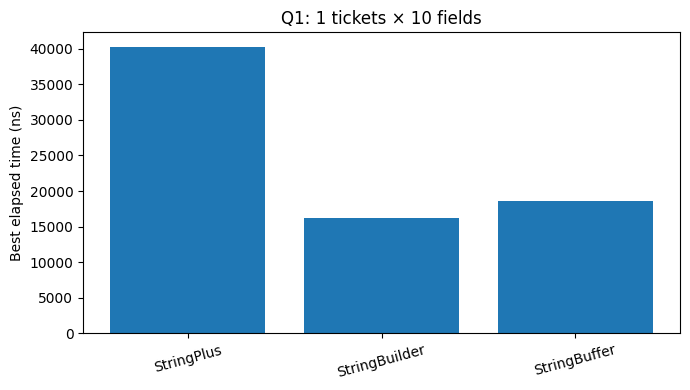

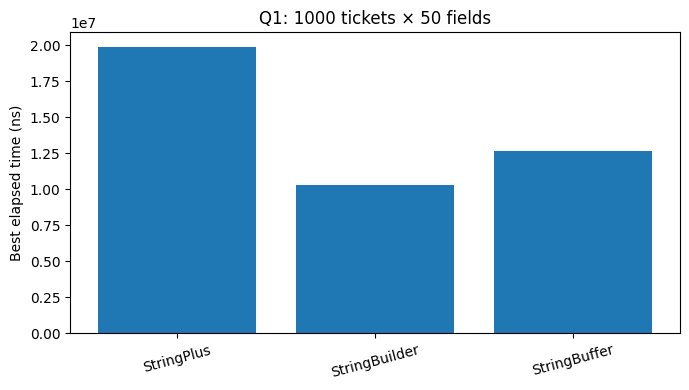

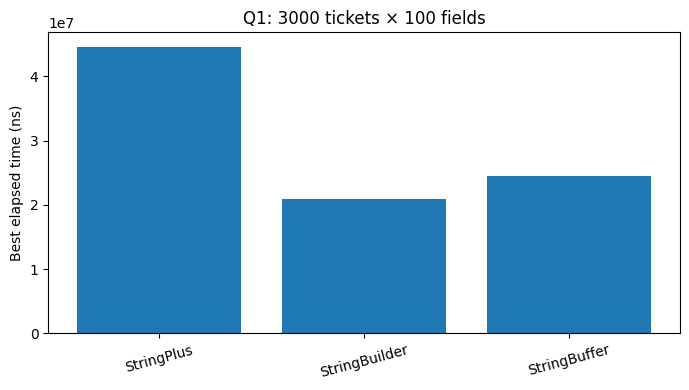

In [5]:
# Q1 comparison
q1[["tickets","fields"]] = q1["workload"].str.split("x", expand=True).astype(int)
q1["workload_label"] = q1["tickets"].astype(str) + " tickets × " + q1["fields"].astype(str) + " fields"
for label, group in q1.groupby("workload_label"):
    plt.figure(figsize=(7,4))
    plt.bar(group["method"], group["nanos"])
    plt.title("Q1: " + label)
    plt.ylabel("Best elapsed time (ns)")
    plt.xticks(rotation=15)
    plt.tight_layout()
    plt.show()

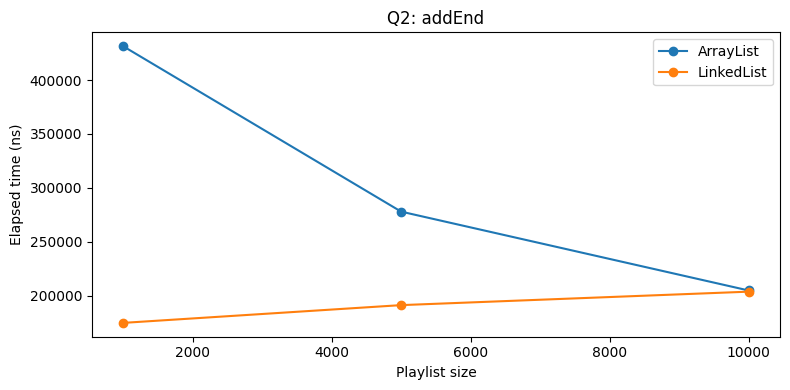

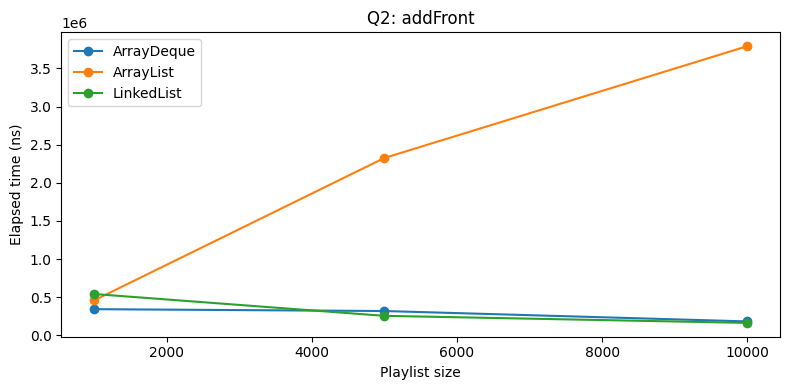

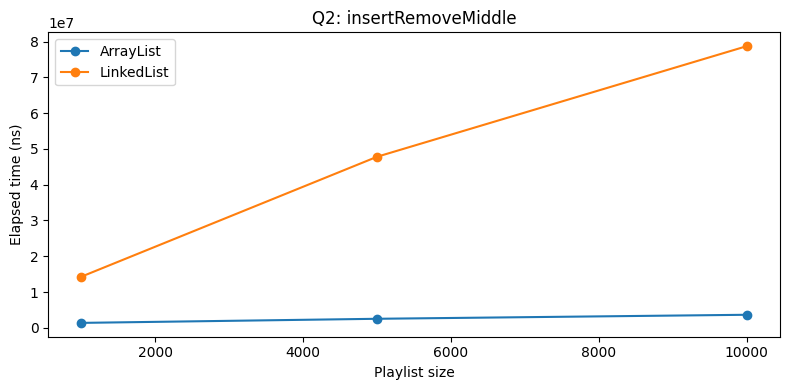

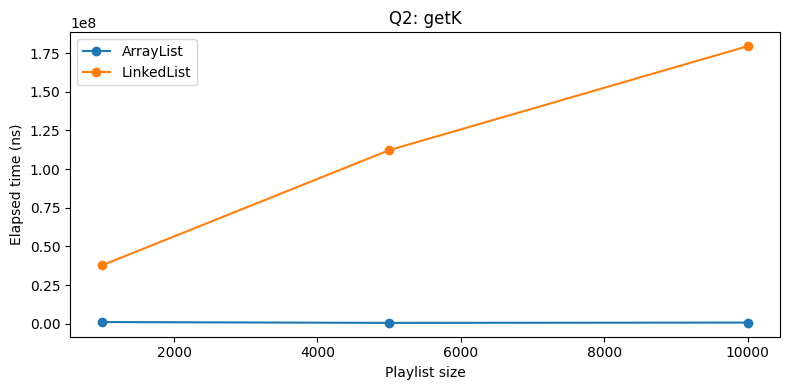

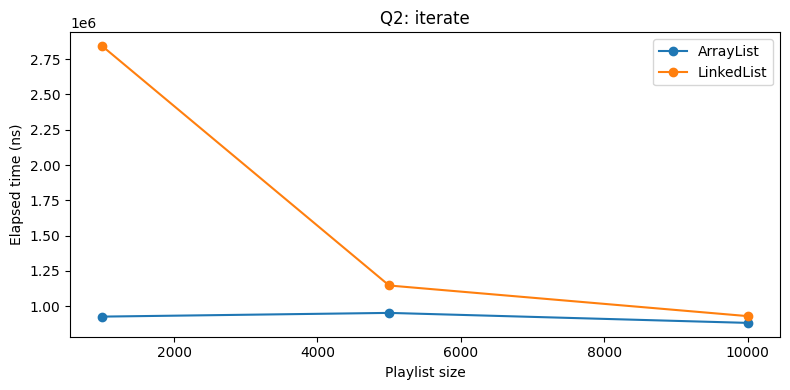

In [6]:
# Q2 selected operations
for op in ["addEnd","addFront","insertRemoveMiddle","getK","iterate"]:
    g = q2[q2.operation == op]
    if not g.empty:
        plt.figure(figsize=(8,4))
        for name, part in g.groupby("structure"):
            plt.plot(part["size"], part["nanos"], marker="o", label=name)
        plt.title("Q2: " + op)
        plt.xlabel("Playlist size")
        plt.ylabel("Elapsed time (ns)")
        plt.legend()
        plt.tight_layout()
        plt.show()

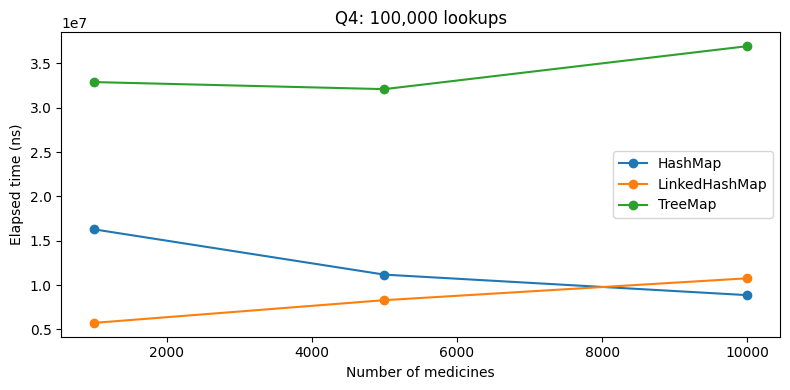

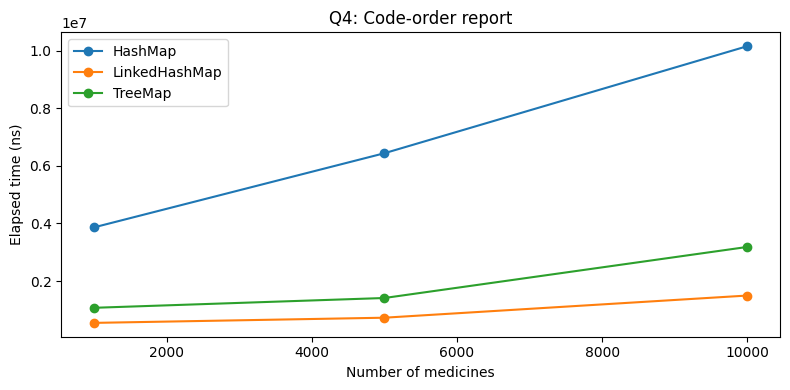

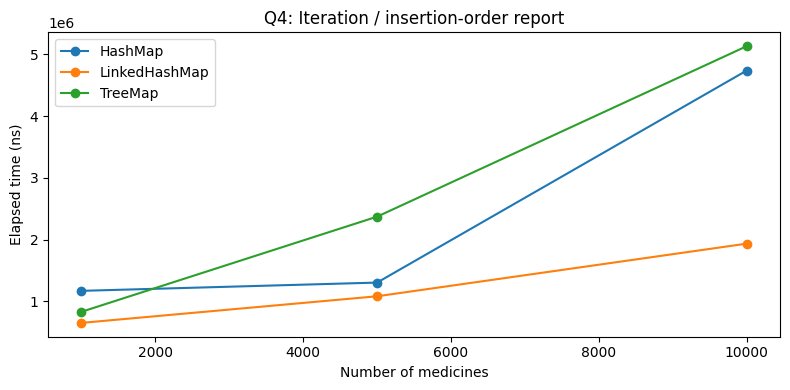

In [7]:
# Q4 map lookup and report costs
for metric, title in [("lookup100kNanos","100,000 lookups"),("codeReportNanos","Code-order report"),("insertionReportNanos","Iteration / insertion-order report")]:
    plt.figure(figsize=(8,4))
    for name, part in q4.groupby("map"):
        plt.plot(part["size"], part[metric], marker="o", label=name)
    plt.title("Q4: " + title)
    plt.xlabel("Number of medicines")
    plt.ylabel("Elapsed time (ns)")
    plt.legend()
    plt.tight_layout()
    plt.show()

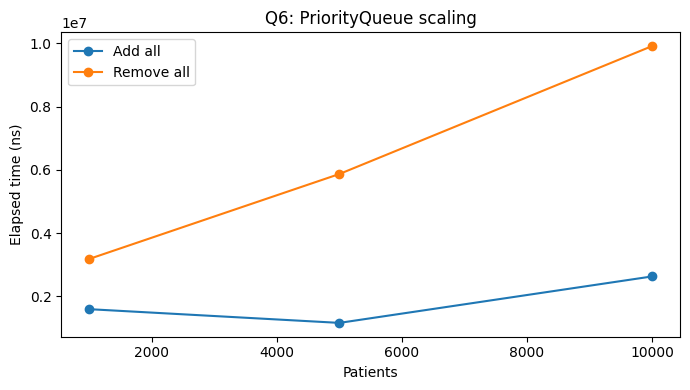

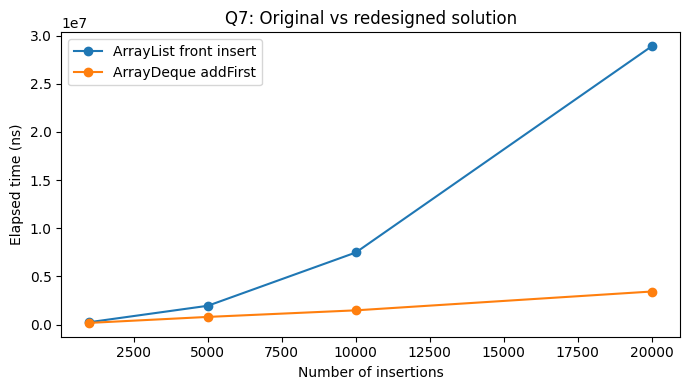

In [8]:
# Q6 and Q7
plt.figure(figsize=(7,4))
plt.plot(q6["size"], q6["addNanos"], marker="o", label="Add all")
plt.plot(q6["size"], q6["removeAllNanos"], marker="o", label="Remove all")
plt.title("Q6: PriorityQueue scaling")
plt.xlabel("Patients")
plt.ylabel("Elapsed time (ns)")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(7,4))
plt.plot(q7["size"], q7["arrayListFrontInsertNanos"], marker="o", label="ArrayList front insert")
plt.plot(q7["size"], q7["arrayDequeFrontInsertNanos"], marker="o", label="ArrayDeque addFirst")
plt.title("Q7: Original vs redesigned solution")
plt.xlabel("Number of insertions")
plt.ylabel("Elapsed time (ns)")
plt.legend()
plt.tight_layout()
plt.show()

## 3. Answers and complexity analysis for the report

### Q1 — String, StringBuilder, StringBuffer
- `String` is immutable. Repeated `+` in a loop creates new intermediate strings and repeatedly copies previous characters.
- Repeated concatenation can require **O(n²)** character copying for `n` appended fields (more precisely, cost depends on total accumulated character length).
- `StringBuilder` uses a mutable buffer: **O(total output characters)** amortized construction; not synchronized, so best for a local per-ticket builder.
- `StringBuffer` is synchronized and thread-safe for individual operations, with synchronization overhead. Use it only if multiple threads truly share the same mutable buffer. For a shared booking log, prefer a synchronized logging mechanism or a lock around a `StringBuilder`; do not share one builder unsafely.
- Alternative: `StringJoiner` / `String.join()` is useful when fields are already available as strings; `String.format()` is convenient but generally has more formatting overhead.
- Estimated intermediate objects: repeated `+` creates many temporary strings; builders create one mutable builder plus the final `String`.

### Q2 — ArrayList, LinkedList, ArrayDeque
| Operation | ArrayList | LinkedList | ArrayDeque |
|---|---:|---:|---:|
| Add at end | amortized O(1) | O(1) | amortized O(1) |
| Add at front | O(n) | O(1) | amortized O(1) |
| Insert middle by index | O(n) | O(n) to locate, O(1) once positioned | no indexed insert |
| Get k-th | O(1) | O(n) | no indexed get |
| Full iteration | O(n) | O(n) | O(n) |
| Per-element storage | array reference | node + links + reference | array slot |

**Recommendation:** ArrayList is suitable when the playlist mostly appends, reads by index, and iterates. Stop recommending it when frequent front/middle insertion/removal dominates. For the “Up Next” queue (add at both ends, remove front), use ArrayDeque. A plain array with manual shifting has O(n) front/middle insertion and O(1) indexed access.

### Q3 — hashCode–equals
- HashSet first uses `hashCode()` to select a bucket, then `equals()` to check possible matches in that bucket.
- The contract requires: if `a.equals(b)` is true, `a.hashCode() == b.hashCode()` must also be true.
- Without overriding `hashCode()`, equal Student objects may be placed in different buckets and both retained.
- Correct implementation: `return Objects.hash(regNo);` because equality is based only on `regNo`.
- Do not mutate fields used by `equals()` / `hashCode()` while an object is stored in a hash collection.
- Alternatives: `HashMap<String,Student>` keyed by registration number gives average O(1) lookup/insert; `TreeSet` with registration-number comparator gives O(log n). Both use O(n) space.

### Q4 — Map choice
| Map | put/get | Iteration order | Suitable report |
|---|---|---|---|
| HashMap | average O(1) | unspecified | neither ordered report directly |
| TreeMap | O(log n) | sorted by key | medicine-code order |
| LinkedHashMap | average O(1) | insertion order | order-added report |

If the wrong map is selected, copy keys and sort them for code order (O(n log n)); insertion order cannot be reconstructed from a plain HashMap. Hashtable is legacy synchronized collection; modern code usually uses HashMap or explicit concurrent collections where needed. The benchmark runs 100,000 lookups at three inventory sizes. Define an acceptable lookup target with your instructor/system context (for example, under 10 ms for the 100,000-lookup batch on this test machine) and report the actual measured result.

### Q5 — Generics and comparator
- Use `Comparator<Team>` for this ranking policy rather than hard-coding one natural ordering in `Team`; the same reusable leaderboard can accept different comparators for players, colleges, or quiz teams.
- Ranking: points descending, goal difference descending, name ascending.
- `Leaderboard<T>` stores `List<T>` and a `Comparator<? super T>`. `ranking()` returns a sorted copy, preserving original insertion data.
- `List<? extends T>` is useful when accepting a list of subtype elements as input (producer/extends).
- One comparator chain sorts in O(n log n). Three stable sorting passes also remain O(n log n) overall (three sorts), with additional passes and sorting work. The comparator chain is easier to maintain and reuse.

### Q6 — PriorityQueue and fairness
- A FIFO Queue cannot choose the most severe patient regardless of arrival time.
- Comparator sorts severity ascending (1 is highest priority), then arrival counter ascending (earlier arrival first).
- `PriorityQueue.offer/poll` are O(log n); peek is O(1); storage is O(n).
- Printing a PriorityQueue directly does not guarantee sorted treatment order; repeatedly `poll()` a copy to display priority order.
- Starvation can occur for severity 5 if severe patients continuously arrive. Aging can improve effective priority based on waiting time, or use a maximum-wait policy.
- 5,000 arrivals/day averages about 0.058 arrivals/second over 24 hours, which is modest for O(log n) operations; real deployment still needs persistence, concurrency, clinical policy validation, and monitoring.
- Alternative: sorted LinkedList insertion O(n), removal next O(1); five FIFO queues provide O(1) admission and service if the highest non-empty severity bucket is checked in fixed five steps.

### Q7 — Diagnose, redesign, validate
- Chosen limitation: ArrayList front insertion shifts existing elements; repeated front insertion can lead to quadratic total movement.
- Objective: reduce repeated front-insertion work.
- Redesign: use ArrayDeque and `addFirst()`, which is amortized O(1); the original ArrayList operation is O(n) per insertion.
- Trade-off: ArrayDeque does not provide indexed access; ArrayList remains better when random access dominates.
- Compare the generated Q7 measurements at identical sizes. Discuss whether the prediction is supported by your own measured timings. Do not claim a fixed speed-up: JVM and machine conditions affect results.

**Important:** Q7 evidence and all benchmark conclusions must be based on the CSV produced by your own Colab execution. The assignment explicitly requires repeated, averaged measurements and raw data, not just a single screenshot.